In [1]:
# CREDIT WISE: LOAN APPROVAL PREDICTION SYSTEM
# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


In [2]:
# 2. LOAD DATASET

df = pd.read_csv("loan_approval_data.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (1000, 20)

First 5 Rows:
   Applicant_ID  Applicant_Income  Coapplicant_Income Employment_Status   Age  \
0           1.0           17795.0              1387.0          Salaried  51.0   
1           2.0            2860.0              2679.0          Salaried  46.0   
2           3.0            7390.0              2106.0          Salaried  25.0   
3           4.0           13964.0              8173.0          Salaried  40.0   
4           5.0           13284.0              4223.0     Self-employed  31.0   

  Marital_Status  Dependents  Credit_Score  Existing_Loans  DTI_Ratio  \
0        Married         0.0         637.0             4.0       0.53   
1        Married         3.0         621.0             2.0       0.30   
2         Single         2.0         674.0             4.0       0.20   
3        Married         2.0         579.0             3.0       0.31   
4         Single         2.0         721.0             1.0       0.29   

   Savings  Collateral_Value  Loa

In [3]:
# 3. DATA CLEANING

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Remove rows where target variable is missing
df = df.dropna(subset=["Loan_Approved"]).copy()

# Convert target values into numerical format
df["Loan_Approved"] = (
    df["Loan_Approved"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

# Check whether target encoding was successful
if df["Loan_Approved"].isnull().any():
    raise ValueError("Unexpected values found in Loan_Approved")

df["Loan_Approved"] = df["Loan_Approved"].astype(int)

# Remove Applicant ID because it is not a useful predictive feature
df = df.drop(columns=["Applicant_ID"], errors="ignore")

print("\nCleaned Dataset:")
print(df.head())




Cleaned Dataset:
   Applicant_Income  Coapplicant_Income Employment_Status   Age  \
0           17795.0              1387.0          Salaried  51.0   
1            2860.0              2679.0          Salaried  46.0   
2            7390.0              2106.0          Salaried  25.0   
3           13964.0              8173.0          Salaried  40.0   
4           13284.0              4223.0     Self-employed  31.0   

  Marital_Status  Dependents  Credit_Score  Existing_Loans  DTI_Ratio  \
0        Married         0.0         637.0             4.0       0.53   
1        Married         3.0         621.0             2.0       0.30   
2         Single         2.0         674.0             4.0       0.20   
3        Married         2.0         579.0             3.0       0.31   
4         Single         2.0         721.0             1.0       0.29   

   Savings  Collateral_Value  Loan_Amount  Loan_Term Loan_Purpose  \
0  19403.0           45638.0      16619.0       84.0     Personal   
1 

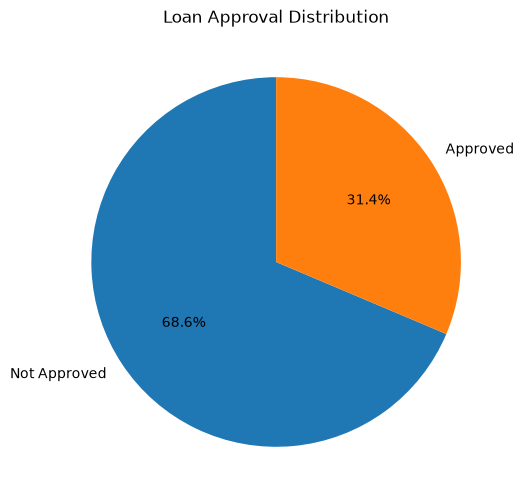

In [4]:
# 4. EXPLORATORY DATA ANALYSIS (EDA)

# 4.1 Class Distribution

class_count = df["Loan_Approved"].value_counts().sort_index()

plt.figure(figsize=(6, 6))

plt.pie(
    class_count,
    labels=["Not Approved", "Approved"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Loan Approval Distribution")
plt.show()


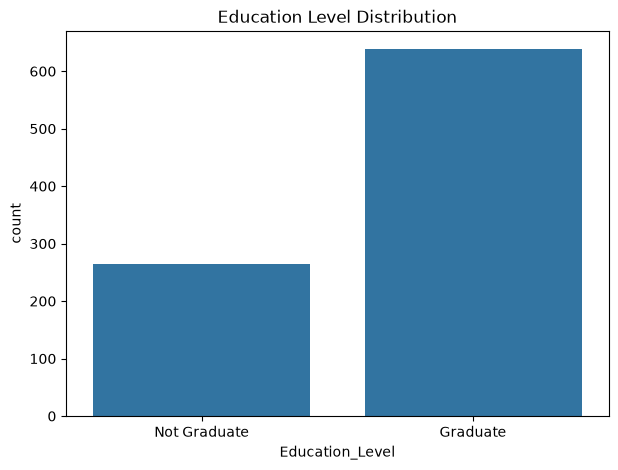

In [5]:
# 4.2 Analyze Education Level

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Education_Level"
)

plt.title("Education Level Distribution")
plt.show()

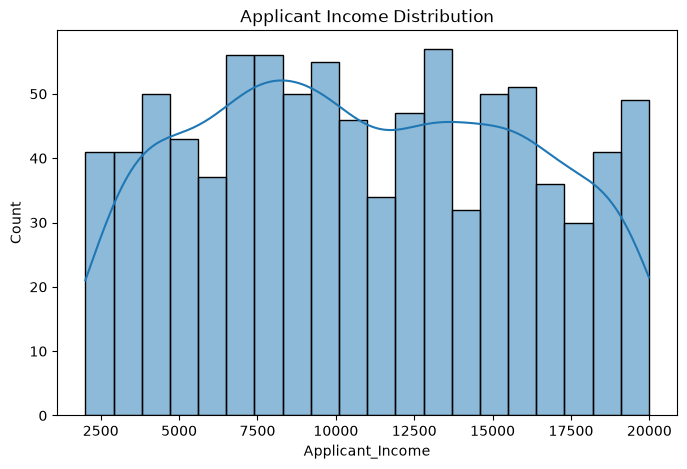

In [6]:
# 4.3 Applicant Income Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Applicant_Income",
    bins=20,
    kde=True
)

plt.title("Applicant Income Distribution")
plt.show()


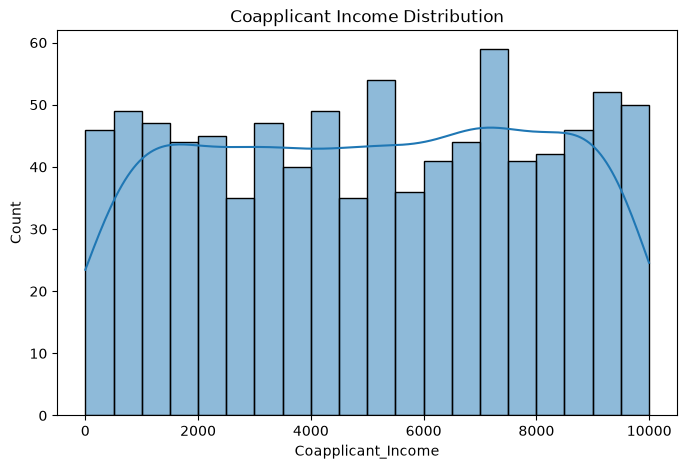

In [7]:
# 4.4 Coapplicant Income Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Coapplicant_Income",
    bins=20,
    kde=True
)

plt.title("Coapplicant Income Distribution")
plt.show()


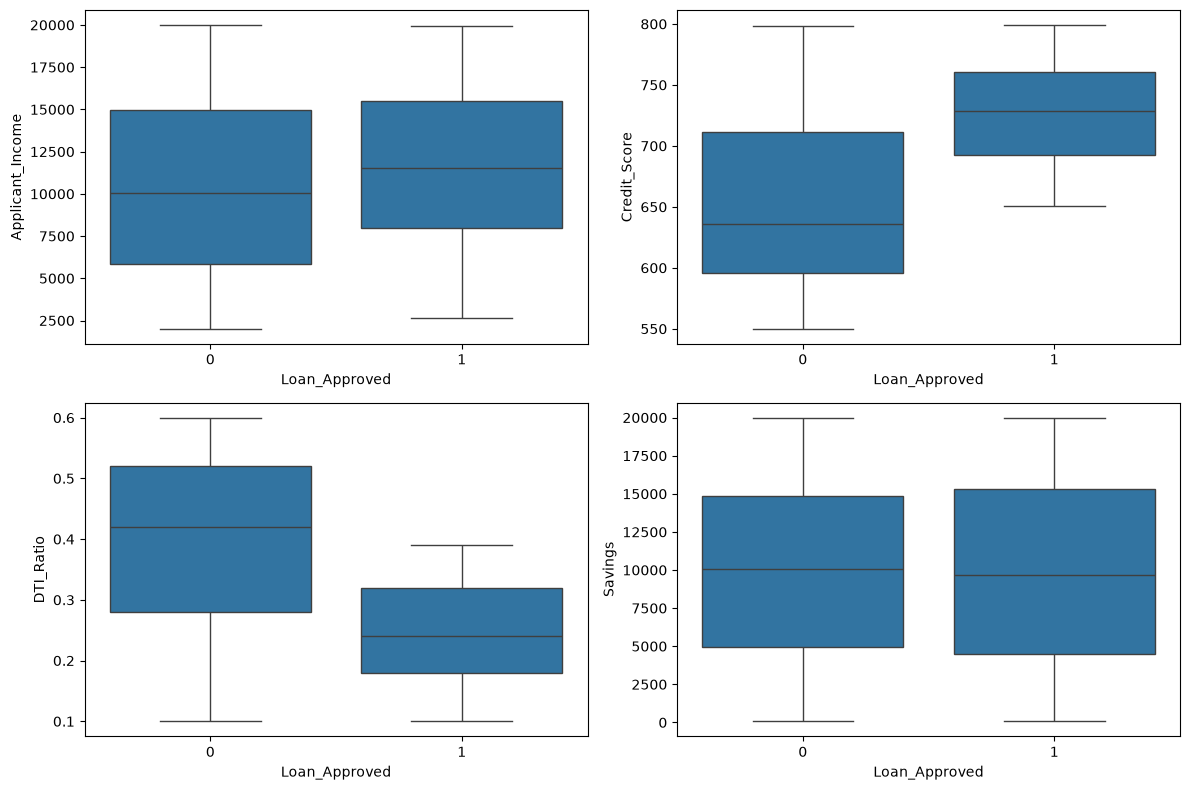

In [8]:
# 4.5 Outlier Analysis

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="Applicant_Income",
    ax=axes[0, 0]
)

sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="Credit_Score",
    ax=axes[0, 1]
)

sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="DTI_Ratio",
    ax=axes[1, 0]
)

sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="Savings",
    ax=axes[1, 1]
)

plt.tight_layout()
plt.show()



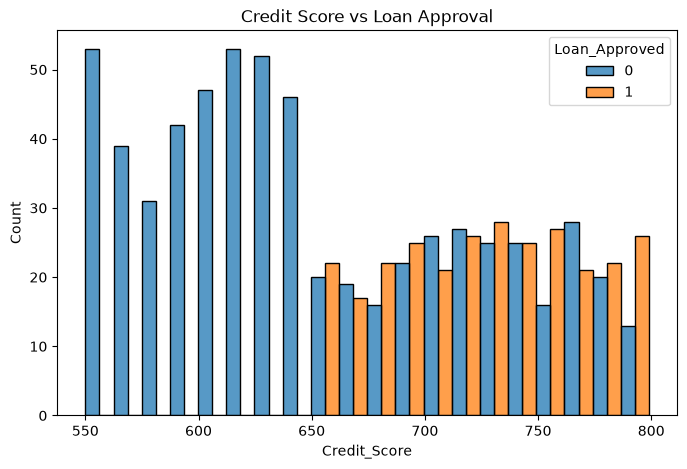

In [9]:
# 4.6 Credit Score vs Loan Approval

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Credit_Score",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)

plt.title("Credit Score vs Loan Approval")
plt.show()


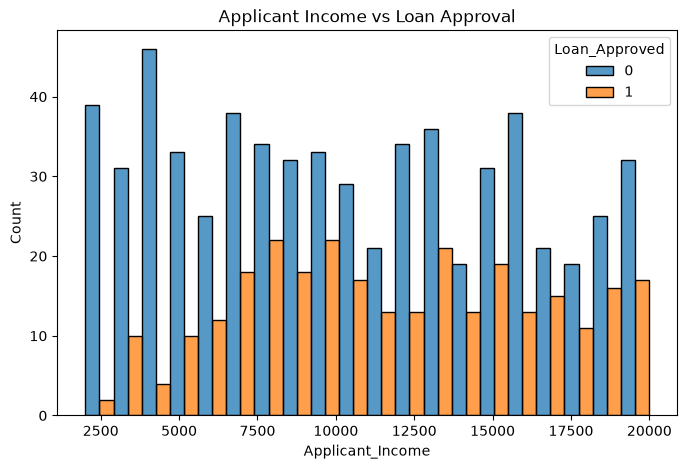

In [10]:
# 4.7 Applicant Income vs Loan Approval

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Applicant_Income",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)

plt.title("Applicant Income vs Loan Approval")
plt.show()

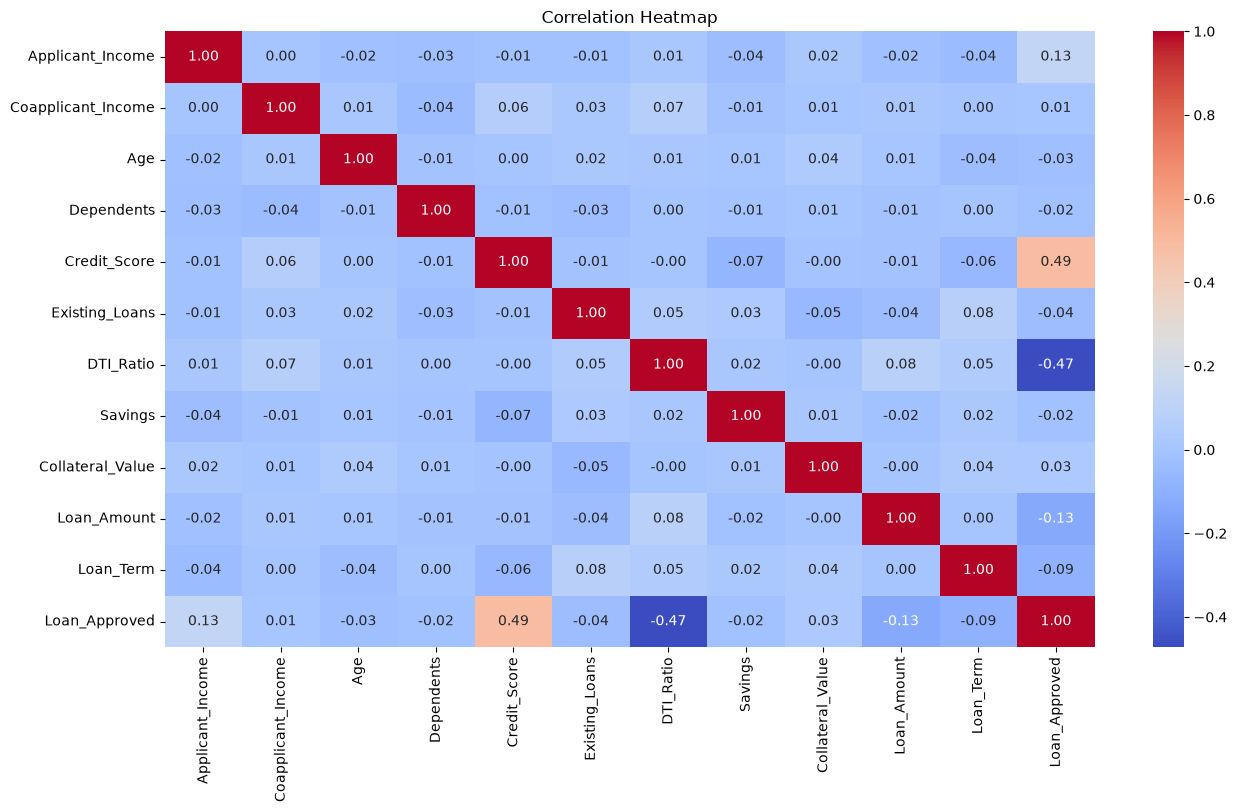


Correlation with Loan Approval:
Loan_Approved         1.000000
Credit_Score          0.489880
Applicant_Income      0.127922
Collateral_Value      0.028128
Coapplicant_Income    0.009340
Dependents           -0.016541
Savings              -0.017319
Age                  -0.028058
Existing_Loans       -0.036184
Loan_Term            -0.092600
Loan_Amount          -0.130477
DTI_Ratio            -0.472434
Name: Loan_Approved, dtype: float64


In [11]:
# 5. CORRELATION ANALYSIS


numeric_df = df.select_dtypes(include="number")

corr_matrix = numeric_df.corr()

plt.figure(figsize=(15, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()


print("\nCorrelation with Loan Approval:")

print(
    corr_matrix["Loan_Approved"]
    .sort_values(ascending=False)
)



In [12]:
# 6. FEATURE ENGINEERING


# Create additional features based on existing numerical features

df["DTI_Ratio_sq"] = df["DTI_Ratio"] ** 2

df["Credit_Score_sq"] = df["Credit_Score"] ** 2

print("\nDataset after Feature Engineering:")

print(df.head())


Dataset after Feature Engineering:
   Applicant_Income  Coapplicant_Income Employment_Status   Age  \
0           17795.0              1387.0          Salaried  51.0   
1            2860.0              2679.0          Salaried  46.0   
2            7390.0              2106.0          Salaried  25.0   
3           13964.0              8173.0          Salaried  40.0   
4           13284.0              4223.0     Self-employed  31.0   

  Marital_Status  Dependents  Credit_Score  Existing_Loans  DTI_Ratio  \
0        Married         0.0         637.0             4.0       0.53   
1        Married         3.0         621.0             2.0       0.30   
2         Single         2.0         674.0             4.0       0.20   
3        Married         2.0         579.0             3.0       0.31   
4         Single         2.0         721.0             1.0       0.29   

   Savings  ...  Loan_Amount  Loan_Term  Loan_Purpose Property_Area  \
0  19403.0  ...      16619.0       84.0      Person

In [13]:
# 7. DEFINE FEATURES AND TARGET


X = df.drop(columns=["Loan_Approved"])

y = df["Loan_Approved"]


# 8. TRAIN TEST SPLIT


X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.2,

    random_state=42,

    stratify=y

)

print("\nTraining Shape:", X_train.shape)

print("Testing Shape:", X_test.shape)




Training Shape: (760, 20)
Testing Shape: (190, 20)


In [14]:
# 9. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns


print("\nNumerical Columns:")
print(list(numerical_cols))

print("\nCategorical Columns:")
print(list(categorical_cols))

# 10. PREPROCESSING PIPELINE


# Numerical preprocessing

num_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler())

])


# Categorical preprocessing

cat_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="most_frequent")),

    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    ))

])


# Combine both preprocessing pipelines

preprocessor = ColumnTransformer([

    ("numerical", num_pipeline, numerical_cols),

    ("categorical", cat_pipeline, categorical_cols)

])


# 11. DEFINE MACHINE LEARNING MODELS


models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB()

}



Numerical Columns:
['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'DTI_Ratio_sq', 'Credit_Score_sq']

Categorical Columns:
['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender', 'Employer_Category']


In [15]:
# 12. TRAIN AND EVALUATE MODELS


results = []

trained_models = {}

for name, model in models.items():

    print("\n" + "=" * 50)

    print(name)

    print("=" * 50)


    # Create complete ML pipeline

    clf = Pipeline([

        ("preprocessor", preprocessor),

        ("model", model)

    ])


    # Train model

    clf.fit(X_train, y_train)


    # Predictions

    y_pred = clf.predict(X_test)


    # Evaluation

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )


    print("Accuracy:", accuracy)

    print("Precision:", precision)

    print("Recall:", recall)

    print("F1 Score:", f1)


    print("\nConfusion Matrix:")

    print(confusion_matrix(y_test, y_pred))


    print("\nClassification Report:")

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


    # Save results

    results.append({

        "Model": name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1

    })


    trained_models[name] = clf



Logistic Regression
Accuracy: 0.8894736842105263
Precision: 0.8421052631578947
Recall: 0.8
F1 Score: 0.8205128205128205

Confusion Matrix:
[[121   9]
 [ 12  48]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.93      0.92       130
           1       0.84      0.80      0.82        60

    accuracy                           0.89       190
   macro avg       0.88      0.87      0.87       190
weighted avg       0.89      0.89      0.89       190


KNN
Accuracy: 0.8736842105263158
Precision: 0.78125
Recall: 0.8333333333333334
F1 Score: 0.8064516129032258

Confusion Matrix:
[[116  14]
 [ 10  50]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.89      0.91       130
           1       0.78      0.83      0.81        60

    accuracy                           0.87       190
   macro avg       0.85      0.86      0.86       190
weighted avg       0.88      0.87      

In [16]:
# 13. MODEL COMPARISON


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print("\nFINAL MODEL COMPARISON:")

print(results_df)


# 14. SELECT BEST MODEL


best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("\nBest Model based on F1 Score:")

print(best_model_name)



# 15. TEST THE SELECTED MODEL


sample_data = X_test.iloc[[0]]

prediction = best_model.predict(sample_data)

if prediction[0] == 1:

    print("\nLoan Approval Prediction: Approved")

else:

    print("\nLoan Approval Prediction: Not Approved")


FINAL MODEL COMPARISON:
                 Model  Accuracy  Precision    Recall  F1 Score
2          Naive Bayes  0.889474   0.809524  0.850000  0.829268
0  Logistic Regression  0.889474   0.842105  0.800000  0.820513
1                  KNN  0.873684   0.781250  0.833333  0.806452

Best Model based on F1 Score:
Naive Bayes

Loan Approval Prediction: Approved


In [17]:
import joblib

joblib.dump(best_model, "credit_wise_model.pkl")

print("Model saved successfully!")

Model saved successfully!
